# 18 — Initialization and gradient flow

| | |
| --- | --- |
| **Prerequisites** | Notebooks 00–17, especially the backward recursion $G_{A^{(\ell)}} = (G_{A^{(\ell+1)}} W^{(\ell+1)}) \odot \varphi'(A^{(\ell)})$ (14), module hooks (15), and activations and their derivatives (16) |
| **You will learn** | Why weights must start random (symmetry breaking); how the variance of activations and of gradients changes from layer to layer, derived from scratch; the LeCun, Xavier/Glorot and Kaiming/He scales and where each comes from; uniform versus normal variants, fan-in versus fan-out, and `nn.init.calculate_gain`; how to measure gradient flow per layer; what `nn.Linear` does by default and why it shrinks deep ReLU networks; how the initial scale alone decides whether a deep MLP trains; orthogonal initialization |
| **Estimated time** | About 3 hours, plus 1–2 hours for the exercises |
| **Compute** | CPU only, about a minute in total. No GPU section: the networks are small, and the effects studied here do not depend on hardware. |

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: mps


In [2]:
import inspect
import math
import warnings

import torch.nn.functional as F
from torch import nn

from dlcourse.data import make_rings, make_spirals
from dlcourse.plotting import COLORS, plot_decision_boundary

f64 = torch.float64

## The motivating problem

Below are two copies of the **same** network: an MLP with 15 hidden ReLU layers of 32 units, trained on the two-arm spirals with the same data, the same optimizer (full-batch gradient descent, `torch.optim.SGD`, notebook 06), the same learning rate and the same number of steps. The only difference is the **scale** of the random numbers the weights start from: every weight is drawn from a normal distribution with standard deviation $c/\sqrt{n_\text{in}}$, where $n_\text{in}$ is the number of inputs to the layer, and the two copies use $c = 0.5$ and $c = \sqrt 2$.

First two helpers that the whole notebook uses: `make_mlp` builds the network as an `nn.Sequential` (notebook 15), and `init_scaled_` overwrites its weights.

In [3]:
def make_mlp(depth, width, act=nn.ReLU, d_in=2, d_out=2):
    """MLP with `depth` linear layers (so depth - 1 hidden layers of `width` units, each followed by `act`)."""
    layers, n = [], d_in
    for _ in range(depth - 1):
        layers += [nn.Linear(n, width), act()]
        n = width
    layers.append(nn.Linear(n, d_out))
    return nn.Sequential(*layers)


def linears(model):
    """The nn.Linear layers of a model, in order."""
    return [m for m in model.modules() if isinstance(m, nn.Linear)]


def init_scaled_(model, c):
    """Every weight ~ N(0, c² / n_in), every bias 0. Weight shape is (n_out, n_in), so n_in = shape[1]."""
    with torch.no_grad():
        for layer in linears(model):
            layer.weight.normal_(0.0, c / math.sqrt(layer.weight.shape[1]))
            layer.bias.zero_()
    return model


def train_full_batch(model, X, y, steps, lr):
    """Full-batch gradient descent on the mean cross-entropy; returns the loss before each step."""
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    losses = []
    for _ in range(steps):
        loss = F.cross_entropy(model(X), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses


X_sp, y_sp = make_spirals(n=200, classes=2, seed=0)   # X: (400, 2) float32, y: (400,) int64
for c in [0.5, math.sqrt(2)]:
    set_seed(0)
    net = init_scaled_(make_mlp(depth=16, width=32), c)
    losses = train_full_batch(net, X_sp, y_sp, steps=1000, lr=0.05)
    acc = (net(X_sp).argmax(dim=1) == y_sp).float().mean().item()
    print(f"c = {c:.3f}: loss {losses[0]:.4f} -> {losses[-1]:.4f}, training accuracy {acc:.2f}")

c = 0.500: loss 0.6931 -> 0.6931, training accuracy 0.60


c = 1.414: loss 0.6947 -> 0.0002, training accuracy 1.00


With $c = 0.5$ the loss stays at $\ln 2 \approx 0.693$ to four digits — the loss of a classifier that outputs 50/50 for every point — and the network learns essentially nothing (its accuracy of 0.60 comes from minute differences between outputs that are all almost exactly 50/50). With $c = \sqrt 2$ it fits the training set almost perfectly. A factor of less than 3 in the initial scale decides between success and complete failure.

**Why does the scale matter so much, and how do we choose it?** This notebook derives the answer from the forward and backward passes of notebook 14: track how the *variance* of activations and gradients changes from one layer to the next, and choose the scale that keeps it constant.

## 1. Symmetry breaking: why the weights must be random

Before asking *how large* the initial weights should be, ask why they are random at all. The simplest idea is to start every weight at the same value, say 0. Consider two units $j$ and $k$ of hidden layer $\ell$. Recall the notation: $A^{(\ell)} = H^{(\ell-1)} W^{(\ell)\top} + \mathbf b^{(\ell)}$ of shape $(N, n_\ell)$, $H^{(\ell)} = \varphi(A^{(\ell)})$, and $W^{(\ell)}$ of shape $(n_\ell, n_{\ell-1})$, so **row $j$** of $W^{(\ell)}$ holds unit $j$'s incoming weights and **column $j$** of $W^{(\ell+1)}$ holds its outgoing weights.

**Claim.** Suppose that at some step, units $j$ and $k$ of layer $\ell$ have identical incoming weights (rows $j$, $k$ of $W^{(\ell)}$ equal), identical biases ($b_j = b_k$), and identical outgoing weights (columns $j$, $k$ of $W^{(\ell+1)}$ equal). Then after a gradient step all three are still true. So by induction they stay true forever: the two units are clones.

**Proof.** *Forward:* column $j$ of $A^{(\ell)}$ is $H^{(\ell-1)}(\text{row } j)^\top + b_j$, the same as column $k$; so columns $j$ and $k$ of $H^{(\ell)}$ are equal too. *Backward* (notebook 14): $G_{H^{(\ell)}} = G_{A^{(\ell+1)}} W^{(\ell+1)}$, and column $j$ of this product is $G_{A^{(\ell+1)}}$ times column $j$ of $W^{(\ell+1)}$ — equal to column $k$. Then $G_{A^{(\ell)}} = G_{H^{(\ell)}} \odot \varphi'(A^{(\ell)})$ also has equal columns $j$, $k$. Finally

- $\partial L/\partial W^{(\ell)} = G_{A^{(\ell)}}^\top H^{(\ell-1)}$: row $j$ is (column $j$ of $G_{A^{(\ell)}}$)$^\top H^{(\ell-1)}$, equal to row $k$;
- $\partial L/\partial \mathbf b^{(\ell)}$ = column sums of $G_{A^{(\ell)}}$: entries $j$, $k$ equal;
- $\partial L/\partial W^{(\ell+1)} = G_{A^{(\ell+1)}}^\top H^{(\ell)}$: column $j$ is $G_{A^{(\ell+1)}}^\top$ times column $j$ of $H^{(\ell)}$, equal to column $k$.

Equal parameters receive equal gradients, so a gradient step $\theta \leftarrow \theta - \eta \nabla_\theta L$ keeps them equal. $\blacksquare$ (The same holds for any optimizer that updates each parameter by a rule applied entry by entry to its own gradient history, such as the momentum and Adam of notebook 19.)

If every weight in the network starts equal, the conditions hold for **every pair** of units in every hidden layer, so each hidden layer behaves like a **single unit** copied $n_\ell$ times, however wide it is. Let's check it on a small tanh network (2 → 8 → 8 → 2) with every weight set to 0.3, trained on the two concentric rings of `make_rings` (notebook 08), which need a closed, curved boundary.

In [4]:
X_ring, y_ring = make_rings(seed=0)                               # X: (800, 2), y: (800,)


def train_and_report(net, name):
    losses = train_full_batch(net, X_ring, y_ring, steps=500, lr=0.5)
    acc = (net(X_ring).argmax(dim=1) == y_ring).float().mean().item()
    W1, W2 = net[0].weight.detach(), net[2].weight.detach()          # (8, 2), (8, 8)
    print(f"{name}: final loss {losses[-1]:.4f}, training accuracy {acc:.3f}")
    print("  first 3 rows of W1 (incoming weights of 3 units):", [[round(v, 4) for v in row] for row in W1[:3].tolist()])
    print(f"  largest difference between any row and row 0: W1 {(W1 - W1[0]).abs().max().item():.2e}, "
          f"W2 {(W2 - W2[0]).abs().max().item():.2e}")
    return net


set_seed(0)
net_const = make_mlp(depth=3, width=8, act=nn.Tanh)
with torch.no_grad():
    for layer in linears(net_const):
        layer.weight.fill_(0.3)
        layer.bias.zero_()
train_and_report(net_const, "constant init 0.3")

set_seed(0)
net_rand = make_mlp(depth=3, width=8, act=nn.Tanh)                  # nn.Linear's default random init
net_rand = train_and_report(net_rand, "random init     ")

constant init 0.3: final loss 0.6021, training accuracy 0.632
  first 3 rows of W1 (incoming weights of 3 units): [[0.9586, 0.5472], [0.9586, 0.5472], [0.9586, 0.5472]]
  largest difference between any row and row 0: W1 0.00e+00, W2 0.00e+00


random init     : final loss 0.0274, training accuracy 0.995
  first 3 rows of W1 (incoming weights of 3 units): [[0.2493, 1.1864], [-0.8233, -0.8546], [-0.828, -0.2694]]
  largest difference between any row and row 0: W1 2.80e+00, W2 3.58e+00


After 500 steps with constant initialization, all 8 rows of $W^{(1)}$ are still identical to the last printed digit (and to all digits: the difference is exactly 0), and so are all rows of $W^{(2)}$. Each hidden layer has learned, but as **one** unit: the network is effectively 2 → 1 → 1 → 2, which cannot draw a closed boundary around the inner ring, and its accuracy stays near 0.63. The randomly initialized copy of the same architecture uses its 8 + 8 units and classifies 99.5% of the points correctly.

Notice what the proof did **not** claim: the two **output** units do not need to stay equal. Their gradients differ because the loss treats the classes differently ($\partial L/\partial Z$ has different columns, notebook 10), so symmetry is broken there automatically. Only units that are interchangeable — same inputs, same role downstream — stay locked together.

**All zeros is even worse.** With $W = 0$ everywhere and $\varphi(0) = 0$ (tanh, ReLU), every hidden activation is 0, so $\partial L/\partial W^{(\ell)} = G^\top H^{(\ell-1)} = 0$ for $\ell \ge 2$, and $G_{H} = G_{A^{(\ell+1)}} W^{(\ell+1)} = 0$ blocks every gradient below the output. Only the output bias can learn:

In [5]:
set_seed(0)
net_zero = make_mlp(depth=3, width=8, act=nn.ReLU)
with torch.no_grad():
    for p in net_zero.parameters():
        p.zero_()
F.cross_entropy(net_zero(X_ring), y_ring).backward()
for name, p in net_zero.named_parameters():
    print(f"{name:9s} shape {str(tuple(p.shape)):7s} largest |gradient| = {p.grad.abs().max().item():.3g}")

0.weight  shape (8, 2)  largest |gradient| = 0
0.bias    shape (8,)    largest |gradient| = 0
2.weight  shape (8, 8)  largest |gradient| = 0
2.bias    shape (8,)    largest |gradient| = 0
4.weight  shape (2, 8)  largest |gradient| = 0
4.bias    shape (2,)    largest |gradient| = 9.31e-09


Only `4.bias` (the output bias) has a nonzero gradient, and after it moves, the hidden activations are still all zero, so the same is true at every later step: all-zero weights are a **fixed point** of gradient descent. (Here even the output bias gradient is 0 up to float32 rounding, about $10^{-8}$: every output is 50/50, the classes are balanced, and $\partial L/\partial \mathbf b = \frac1N\sum_i(\hat{\mathbf p}_i - \mathbf y_i) = 0$. The network does not move at all.)

**The fix** is to draw the weights at random, independently: then no two units are interchangeable, and they receive different gradients from the first step. **Biases can start at 0**: once the weights are random, the units already differ, so random biases add nothing for symmetry breaking. The rest of the notebook is about the remaining choice — the **scale** of the random weights.

### Checkpoint 1.1

Write `unit_spread(W)`: for a weight matrix `W` of shape `(n_out, n_in)`, return the largest absolute difference between any row and row 0, as a Python float. It should be exactly 0 for the hidden layers of `net_const` and clearly positive for `net_rand`.

<details>
<summary><b>💡 Hint</b></summary>

`(W - W[0]).abs().max().item()`; broadcasting subtracts row 0 from every row. Detach first if `W` requires grad.

</details>

In [ ]:
def unit_spread(W):
    # YOUR CODE HERE
    raise NotImplementedError


print("constant init:", unit_spread(net_const[0].weight), unit_spread(net_const[2].weight))
print("random init  :", unit_spread(net_rand[0].weight), unit_spread(net_rand[2].weight))

In [ ]:
check(isinstance(unit_spread(torch.ones(3, 2)), float), "unit_spread should return a Python float")
check(unit_spread(net_const[0].weight) == 0.0 and unit_spread(net_const[2].weight) == 0.0,
      "the hidden layers of net_const should have spread exactly 0")
check(unit_spread(net_rand[0].weight) > 0.1, "net_rand's first layer should have clearly different rows")
check_close(unit_spread(torch.tensor([[1.0, 2.0], [1.5, 2.0], [0.0, 4.0]])), 2.0, "unit_spread on a small example")
passed("Checkpoint 1.1")

## 2. Forward: how the variance of activations propagates

Take one unit of layer $\ell$ and one example, and drop the bias (we start biases at 0). Its pre-activation is a sum over the $n = n_{\ell-1}$ inputs of the layer (its **fan-in**):

$$a = \sum_{j=1}^{n} w_j h_j .$$

**Assumptions.** The weights $w_j$ are independent, with mean 0 and variance $\sigma_w^2$. They are independent of the inputs $h_j$ (true at initialization: $h_j$ depends only on the data and the *earlier* layers' weights). The $h_j$ all have the same distribution.

**Mean.** $\mathbb E[a] = \sum_j \mathbb E[w_j]\,\mathbb E[h_j] = 0$, by independence and $\mathbb E[w_j] = 0$.

**Variance.** Since the mean is 0, $\operatorname{Var}(a) = \mathbb E[a^2] = \sum_j \sum_k \mathbb E[w_j w_k]\,\mathbb E[h_j h_k]$. For $j \ne k$, $\mathbb E[w_j w_k] = \mathbb E[w_j]\mathbb E[w_k] = 0$; for $j = k$ it is $\sigma_w^2$. So

$$\boxed{\operatorname{Var}(a) = n\,\sigma_w^2\,\mathbb E[h^2].}$$

Note $\mathbb E[h^2]$, the **second moment**, not $\operatorname{Var}(h)$: they differ when $h$ has a nonzero mean, as ReLU and sigmoid outputs do ($\mathbb E[h^2] = \operatorname{Var}(h) + \mathbb E[h]^2$). We did not need the $h_j$ to be independent of each other: the cross terms vanish because of the weights. Let's check the formula by simulation, with ReLU outputs (mean $\ne 0$) as the inputs $h$:

In [8]:
gen = torch.Generator().manual_seed(0)
n, sigma_w, trials = 100, 0.3, 200_000
h = torch.relu(torch.randn(trials, n, generator=gen, dtype=f64))     # (trials, n): inputs with nonzero mean
w = sigma_w * torch.randn(trials, n, generator=gen, dtype=f64)       # (trials, n): fresh weights for each trial
a = (w * h).sum(dim=1)                                               # (trials,): one pre-activation per trial
print(f"measured Var(a)            = {a.var().item():.4f}")
print(f"n σ_w² E[h²]               = {n * sigma_w**2 * (h**2).mean().item():.4f}")
print(f"n σ_w² Var(h)  (wrong)     = {n * sigma_w**2 * h.var().item():.4f}")

measured Var(a)            = 4.5007
n σ_w² E[h²]               = 4.5055
n σ_w² Var(h)  (wrong)     = 3.0710


The formula with $\mathbb E[h^2]$ matches to within Monte Carlo error; the version with $\operatorname{Var}(h)$ is off by a factor of about 1.5.

**From one layer to the next.** Write $v_\ell = \operatorname{Var}(a^{(\ell)})$. Then $v_\ell = n_{\ell-1}\sigma_w^2\,\mathbb E[\varphi(a^{(\ell-1)})^2]$, and what remains is to express $\mathbb E[\varphi(a)^2]$ in terms of $v_{\ell-1}$.

- **Linear** ($\varphi(a) = a$): $\mathbb E[h^2] = v_{\ell-1}$, so $v_\ell = n\sigma_w^2\,v_{\ell-1}$, and after $L$ layers $v_L = (n\sigma_w^2)^L\,v_0$ — **geometric** in depth. The only scale that neither shrinks nor explodes is $n\sigma_w^2 = 1$, i.e.
$$\sigma_w^2 = \frac{1}{n_\text{in}} \qquad \text{(LeCun et al., 1998, "Efficient BackProp").}$$
The same rule applies to **tanh** to first order, because $\tanh(a) \approx a$ near 0 (Exercise 1 looks at what the higher-order terms do).
- **ReLU**: the weights are symmetric around 0, so $a$ is symmetric too ($a$ and $-a$ have the same distribution). Then $\mathbb E[\operatorname{relu}(a)^2] = \mathbb E[a^2 \mathbb 1\{a > 0\}] = \frac12 \mathbb E[a^2] = \frac12 v$: by symmetry the positive half carries exactly half of $\mathbb E[a^2]$. So $v_\ell = \frac12 n\sigma_w^2\,v_{\ell-1}$, and the scale that keeps it constant is
$$\sigma_w^2 = \frac{2}{n_\text{in}} \qquad \text{(He, Zhang, Ren and Sun, 2015, "Delving Deep into Rectifiers"; called Kaiming or He initialization).}$$

The ReLU step needs only symmetry, not normality. Checked with three symmetric distributions:

In [9]:
gen = torch.Generator().manual_seed(1)
m = 1_000_000
samples = {
    "normal N(0, 3²)": 3 * torch.randn(m, generator=gen, dtype=f64),
    "uniform U(-2, 2)": 4 * torch.rand(m, generator=gen, dtype=f64) - 2,
    "Laplace (heavy tails)": torch.distributions.Laplace(0.0, 1.0).sample((m,)).double(),
}
for name, a in samples.items():
    print(f"{name:22s}: E[relu(a)²] / E[a²] = {(torch.relu(a)**2).mean().item() / (a**2).mean().item():.4f}")

normal N(0, 3²)       : E[relu(a)²] / E[a²] = 0.4994
uniform U(-2, 2)      : E[relu(a)²] / E[a²] = 0.4991
Laplace (heavy tails) : E[relu(a)²] / E[a²] = 0.5004


All three ratios are $0.5$ to within sampling error. (The Laplace samples come from `torch.distributions`, which uses the global seed set in the setup cell.) The symmetry assumption matters; a **negative control** with an asymmetric distribution — for example a pre-activation with a positive mean, as a nonzero bias would produce — breaks the rule:

In [10]:
a_shifted = 1.0 + torch.randn(m, generator=gen, dtype=f64)          # N(1, 1): not symmetric about 0
print(f"N(1, 1) (asymmetric) : E[relu(a)²] / E[a²] = {(torch.relu(a_shifted)**2).mean().item() / (a_shifted**2).mean().item():.4f}")

N(1, 1) (asymmetric) : E[relu(a)²] / E[a²] = 0.9624


Here most of the mass is positive, so ReLU keeps far more than half of $\mathbb E[a^2]$. With zero biases and symmetric weights, the pre-activations at initialization are symmetric, so the rule applies; once training has moved the weights and biases, it need not.

### Simulation through 50 layers

Now check the prediction where it matters: in a deep stack. We push $N = 1000$ standard-normal inputs of width 256 through 50 layers of width 256, with weights $\sim \mathcal N(0, c^2/n)$, and record the standard deviation of the activations $H^{(\ell)}$ after each layer, for four scales $c$: too small ($0.5$), LeCun ($c = 1$), Kaiming ($c = \sqrt 2$), and too large ($c = 2$). The prediction for ReLU: each layer multiplies $\mathbb E[h^2]$ by $\frac12 n \sigma_w^2 = c^2/2$, so the standard deviation by $c/\sqrt 2$ — about $0.35$, $0.71$, $1$ and $1.41$ per layer.

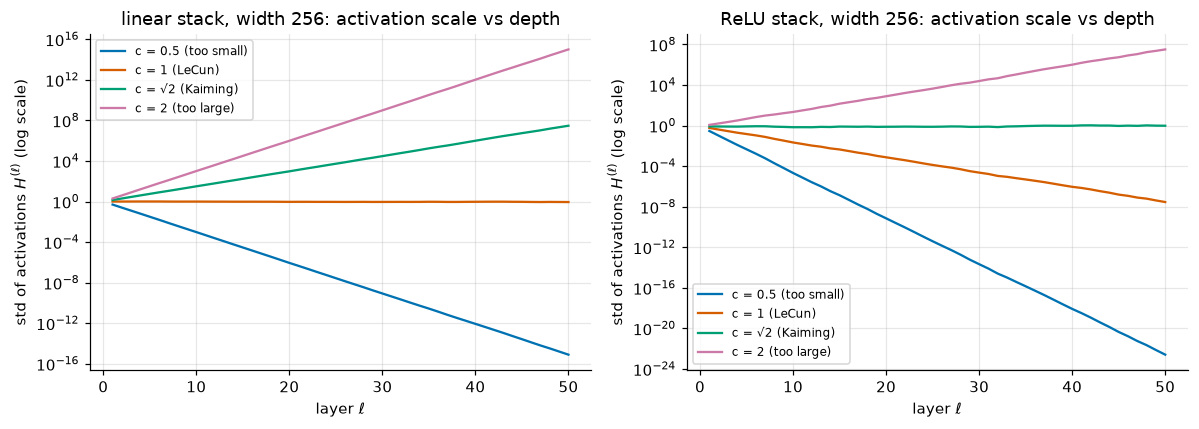

ReLU, c = 0.5 (too small) : std at layers 1, 10, 50 = 0.293, 2.1e-05, 2.55e-23
ReLU, c = 1 (LeCun)       : std at layers 1, 10, 50 = 0.585, 0.0215, 2.87e-08
ReLU, c = √2 (Kaiming)    : std at layers 1, 10, 50 = 0.828, 0.689, 0.963
ReLU, c = 2 (too large)   : std at layers 1, 10, 50 = 1.17, 22.1, 3.23e+07


In [11]:
def propagate(act, c, depth=50, width=256, n_examples=1000, seed=0):
    """Push N(0, 1) inputs through `depth` layers W ~ N(0, c²/width), zero bias. Returns the std of H after each layer."""
    gen = torch.Generator().manual_seed(seed)
    h = torch.randn(n_examples, width, generator=gen)                  # (N, width) = H^(0)
    stds = []
    for _ in range(depth):
        W = torch.randn(width, width, generator=gen) * c / math.sqrt(width)   # (n_out, n_in)
        h = act(h @ W.T)                                               # (N, width)
        stds.append(h.std().item())
    return stds


identity = lambda a: a
scales = {"c = 0.5 (too small)": 0.5, "c = 1 (LeCun)": 1.0, "c = √2 (Kaiming)": math.sqrt(2), "c = 2 (too large)": 2.0}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
stds_relu = {}
for ax, (act_name, act) in zip(axes, [("linear", identity), ("ReLU", torch.relu)]):
    for k, (label, c) in enumerate(scales.items()):
        s = propagate(act, c)
        if act_name == "ReLU":
            stds_relu[label] = s
        ax.semilogy(range(1, 51), s, color=COLORS[k], label=label)
    ax.set_xlabel("layer $\\ell$")
    ax.set_ylabel("std of activations $H^{(\\ell)}$ (log scale)")
    ax.set_title(f"{act_name} stack, width 256: activation scale vs depth")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
for label, s in stds_relu.items():
    print(f"ReLU, {label:20s}: std at layers 1, 10, 50 = {s[0]:.3g}, {s[9]:.3g}, {s[49]:.3g}")

On a log scale, geometric growth or decay is a straight line, and that is what we see. For the **linear** stack, LeCun ($c = 1$) keeps the scale flat, while $c = \sqrt 2$ already explodes (by $\sqrt 2$ per layer, $2^{25} \approx 3 \times 10^7$ after 50 layers). For **ReLU**, LeCun now *shrinks* the activations (by $1/\sqrt 2$ per layer: a factor $2^{-25}$ over 50 layers), and **Kaiming** is the flat line. The too-small and too-large scales reach $10^{-20}$ and $10^{7}$.

The Kaiming curve is flat on average but wanders (between about 0.6 and 0.9 here). The derivation computes the expectation over the random weights; any single draw of 50 finite matrices multiplies the scale by slightly different factors each layer, and these random factors accumulate like a random walk in $\log(\text{std})$. The wandering shrinks as the width grows. Section 7 shows one way to remove it.

### Checkpoint 2.1

By hand, using only the derivation:

1. `he_std_256`: the Kaiming standard deviation $\sigma_w$ for a layer with fan-in 256.
2. `relu_lecun_ratio_10`: in a ReLU stack with LeCun initialization ($\sigma_w^2 = 1/n$), by what factor does the **standard deviation** of the activations change over 10 layers?

The check compares part 2 with the simulation above (`stds_relu`).

<details>
<summary><b>💡 Hint</b></summary>

$\sigma_w = \sqrt{2/n}$. Per ReLU layer, $\mathbb E[h^2]$ is multiplied by $\frac12 n\sigma_w^2$; the standard deviation by the square root of that.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"he_std_256 = {he_std_256:.4f}, relu_lecun_ratio_10 = {relu_lecun_ratio_10:.5f}")

In [ ]:
check_close(he_std_256, 0.0883883476, "he_std_256", rtol=1e-6)
_measured = stds_relu["c = 1 (LeCun)"][19] / stds_relu["c = 1 (LeCun)"][9]   # layer 20 vs layer 10
print(f"measured ratio of std, layer 20 / layer 10: {_measured:.5f}")
check_close(relu_lecun_ratio_10, 2 ** -5, "relu_lecun_ratio_10", rtol=1e-6)
check(abs(math.log(_measured / relu_lecun_ratio_10)) < 0.3, "the prediction should match the simulation within about 30%")
passed("Checkpoint 2.1")

## 3. Backward: gradients, fan-out, and the Glorot compromise

The forward pass is only half the story: the **gradients** must also keep their scale as they travel back to the early layers. The backward recursion of notebook 14 is

$$G_{A^{(\ell)}} = \big(G_{A^{(\ell+1)}} W^{(\ell+1)}\big) \odot \varphi'(A^{(\ell)}).$$

For one unit $j$ of layer $\ell$ and one example, that reads $g_j = \varphi'(a_j)\sum_{i} g'_i\, w_{ij}$, where the sum runs over the $n_{\ell+1}$ units of the next layer — the unit's **fan-out**. It has exactly the shape of the forward sum, with the fan-out in place of the fan-in. Assuming, as Glorot and Bengio (2010) do, that the $g'_i$, the weights and $\varphi'(a_j)$ are independent (an approximation: the same weights were used in the forward pass), the same calculation gives

$$\operatorname{Var}(g) = n_\text{out}\,\sigma_w^2\,\operatorname{Var}(g')\;\mathbb E[\varphi'(a)^2].$$

For ReLU, $\varphi'(a) = \mathbb 1\{a > 0\}$, so $\mathbb E[\varphi'^2] = P(a > 0) = \frac12$; for a linear layer it is 1. So **backward** stability asks for $\sigma_w^2 = 1/n_\text{out}$ (linear) or $2/n_\text{out}$ (ReLU), while the forward pass asked for $1/n_\text{in}$ or $2/n_\text{in}$.

The weight gradient needs both: $\partial L/\partial W^{(\ell)} = G_{A^{(\ell)}}^\top H^{(\ell-1)}$ is a product of a backward quantity and a forward one.

**Glorot and Bengio (2010)**, "Understanding the difficulty of training deep feedforward neural networks", noted that both conditions hold only when $n_\text{in} = n_\text{out}$, and proposed the compromise

$$\sigma_w^2 = \frac{2}{n_\text{in} + n_\text{out}},$$

the reciprocal of the average fan. This is **Xavier** (or Glorot) initialization; for square layers it equals LeCun's $1/n$.

**How much does the mismatch cost?** In a stack of linear layers with widths $n_0, n_1, \dots, n_L$ and fan-in initialization, layer $\ell$ multiplies the backward variance by $n_\ell \sigma_w^2 = n_\ell / n_{\ell-1}$. Over the whole stack the product **telescopes**:

$$\prod_{\ell=1}^{L} \frac{n_\ell}{n_{\ell-1}} = \frac{n_L}{n_0}.$$

So the gradient variance changes by the ratio of the first and last widths — not exponentially in depth. He et al. (2015) make the same observation and conclude that either the fan-in or the fan-out version works, as long as one of them is used consistently. Let's verify with a widening linear stack, 16 → 32 → ⋯ → 1024 (6 layers): the forward variance should change by $\prod n_\text{in}\sigma_w^2$ and the backward variance by $\prod n_\text{out}\sigma_w^2$. To measure the backward variance we put a random upstream gradient $G$ (standard normal, shape $(N, 1024)$) at the output: backpropagating the scalar $\sum (\text{out} \odot G)$ makes autograd compute exactly $G W^{(L)} \cdots W^{(1)}$.

In [14]:
widths = [16, 32, 64, 128, 256, 512, 1024]
modes = {"fan_in: 1/n_in": lambda fi, fo: 1 / fi,
         "fan_out: 1/n_out": lambda fi, fo: 1 / fo,
         "Glorot: 2/(n_in+n_out)": lambda fi, fo: 2 / (fi + fo)}
gen = torch.Generator().manual_seed(0)
x_in = torch.randn(2000, widths[0], generator=gen, requires_grad=True)   # (N, 16)
G_out = torch.randn(2000, widths[-1], generator=gen)                    # (N, 1024) upstream gradient
print(f"{'mode':24s} {'forward Var(out)/Var(in)':>26s} {'predicted':>10s} {'backward Var(G_in)/Var(G_out)':>31s} {'predicted':>10s}")
for name, var_fn in modes.items():
    out, pred_f, pred_b = x_in, 1.0, 1.0
    for fi, fo in zip(widths[:-1], widths[1:]):
        var = var_fn(fi, fo)
        W = torch.randn(fo, fi, generator=gen) * math.sqrt(var)         # (n_out, n_in)
        out = out @ W.T
        pred_f *= fi * var
        pred_b *= fo * var
    x_in.grad = None
    (out * G_out).sum().backward()
    fwd = out.var().item() / x_in.var().item()
    bwd = x_in.grad.var().item() / G_out.var().item()
    print(f"{name:24s} {fwd:26.3f} {pred_f:10.3f} {bwd:31.3f} {pred_b:10.3f}")

mode                       forward Var(out)/Var(in)  predicted   backward Var(G_in)/Var(G_out)  predicted
fan_in: 1/n_in                                1.102      1.000                          71.018     64.000
fan_out: 1/n_out                              0.016      0.016                           1.018      1.000
Glorot: 2/(n_in+n_out)                        0.088      0.088                           5.670      5.619


Every measurement agrees with its prediction to within about 10% (the fluctuation of a single draw of random matrices, as in Section 2). Fan-in keeps the forward scale and lets the gradient variance grow by $1024/16 = 64$; fan-out does the opposite; Glorot splits the difference ($(2/3)^6 \approx 0.088$ forward, $(4/3)^6 \approx 5.6$ backward). None of these is a disaster, because the factors depend on the width ratio, not on depth. A wrong **constant** in $\sigma_w^2$ (Section 2) is far worse: it compounds every layer.

### Uniform versus normal, and `torch.nn.init`

Only the variance entered the derivation, so any zero-mean distribution with the right variance will do. The usual alternative to the normal is the uniform $U(-a, a)$, whose variance is

$$\int_{-a}^{a} x^2\,\frac{1}{2a}\,dx = \frac{1}{2a}\cdot\frac{2a^3}{3} = \frac{a^2}{3}, \qquad \text{so } a = \sqrt 3\,\sigma_w \text{ for a target standard deviation } \sigma_w.$$

PyTorch's `torch.nn.init` provides all four combinations. Each multiplies the standard deviation by a **gain** that depends on the activation:

| function | standard deviation | uniform bound |
| --- | --- | --- |
| `xavier_normal_(w, gain)` | $\text{gain}\cdot\sqrt{2/(n_\text{in}+n_\text{out})}$ | — |
| `xavier_uniform_(w, gain)` | same | $\text{gain}\cdot\sqrt{6/(n_\text{in}+n_\text{out})}$ |
| `kaiming_normal_(w, a, mode, nonlinearity)` | $\text{gain}/\sqrt{\text{fan}}$ | — |
| `kaiming_uniform_(w, a, mode, nonlinearity)` | same | $\text{gain}\cdot\sqrt{3/\text{fan}}$ |

Here $\text{fan}$ is $n_\text{in}$ (`mode="fan_in"`, the default) or $n_\text{out}$ (`mode="fan_out"`). For an `nn.Linear` weight of shape `(out_features, in_features)`, the fan-in is `weight.shape[1]` and the fan-out `weight.shape[0]`.

The gain is $\sqrt{1/\text{(the factor by which } \varphi \text{ shrinks } \mathbb E[h^2])}$: for ReLU we derived the factor $\frac12$, so the gain is $\sqrt 2$. For Leaky ReLU with negative slope $s$ (notebook 16), $\mathbb E[\varphi(a)^2] = \frac12 v + \frac12 s^2 v$, so the gain is $\sqrt{2/(1 + s^2)}$. `nn.init.calculate_gain` returns these:

In [15]:
for nl, param in [("linear", None), ("sigmoid", None), ("tanh", None), ("relu", None), ("leaky_relu", 0.01), ("leaky_relu", math.sqrt(5)), ("selu", None)]:
    g = nn.init.calculate_gain(nl, param)
    print(f"calculate_gain({nl!r}{'' if param is None else f', {param:.4g}'}) = {g:.6f}")
print(f"√2 = {math.sqrt(2):.6f},  √(2 / (1 + 0.01²)) = {math.sqrt(2 / (1 + 0.01**2)):.6f},  √(2 / (1 + 5)) = {math.sqrt(2 / 6):.6f}")

calculate_gain('linear') = 1.000000
calculate_gain('sigmoid') = 1.000000
calculate_gain('tanh') = 1.666667
calculate_gain('relu') = 1.414214
calculate_gain('leaky_relu', 0.01) = 1.414143
calculate_gain('leaky_relu', 2.236) = 0.577350
calculate_gain('selu') = 0.750000
√2 = 1.414214,  √(2 / (1 + 0.01²)) = 1.414143,  √(2 / (1 + 5)) = 0.577350


The ReLU and Leaky ReLU gains match the derivation. The other values are **conventions, not derivations**: the gain for sigmoid is 1 although $\sigma'(0) = \frac14$; tanh's $5/3$ is an empirical choice that PyTorch documents without derivation (Exercise 1 shows what it does); SELU's $3/4$ is chosen to suit that activation's self-normalizing design. The odd-looking `leaky_relu` with slope $\sqrt 5$ reappears in Section 5.

Now check that `nn.init` produces the standard deviations and bounds in the table, on a non-square weight of shape `(300, 100)`, so that $n_\text{in} = 100$ and $n_\text{out} = 300$:

In [16]:
torch.manual_seed(0)
fan_in, fan_out = 100, 300
inits = [
    ("xavier_normal_", lambda w: nn.init.xavier_normal_(w), math.sqrt(2 / (fan_in + fan_out)), False),
    ("xavier_uniform_", lambda w: nn.init.xavier_uniform_(w), math.sqrt(2 / (fan_in + fan_out)), True),
    ("kaiming_normal_ (relu, fan_in)", lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu"), math.sqrt(2 / fan_in), False),
    ("kaiming_normal_ (relu, fan_out)", lambda w: nn.init.kaiming_normal_(w, mode="fan_out", nonlinearity="relu"), math.sqrt(2 / fan_out), False),
    ("kaiming_uniform_ (relu, fan_in)", lambda w: nn.init.kaiming_uniform_(w, nonlinearity="relu"), math.sqrt(2 / fan_in), True),
]
for name, init_fn, std_pred, uniform in inits:
    w = torch.empty(fan_out, fan_in)                  # nn.Linear layout: (out, in)
    init_fn(w)
    bound = f"   max |w| {w.abs().max().item():.4f} vs bound √3·std {math.sqrt(3) * std_pred:.4f}" if uniform else ""
    print(f"{name:32s}: std {w.std().item():.4f} vs predicted {std_pred:.4f}{bound}")

xavier_normal_                  : std 0.0708 vs predicted 0.0707
xavier_uniform_                 : std 0.0704 vs predicted 0.0707   max |w| 0.1225 vs bound √3·std 0.1225
kaiming_normal_ (relu, fan_in)  : std 0.1422 vs predicted 0.1414
kaiming_normal_ (relu, fan_out) : std 0.0818 vs predicted 0.0816
kaiming_uniform_ (relu, fan_in) : std 0.1417 vs predicted 0.1414   max |w| 0.2449 vs bound √3·std 0.2449


With 30 000 entries, each empirical standard deviation is within about 1% of the formula, and the uniform draws fill their interval right up to the bound.

### Checkpoint 3.1

A weight of shape `(300, 100)` (`nn.Linear(100, 300)`) is followed by tanh. By hand:

1. `xavier_tanh_bound`: the bound $a$ that `nn.init.xavier_uniform_(w, gain=nn.init.calculate_gain("tanh"))` uses.
2. `kaiming_fan_out_std`: the standard deviation that `nn.init.kaiming_normal_(w, mode="fan_out", nonlinearity="relu")` uses for the same shape.

<details>
<summary><b>💡 Hint</b></summary>

The tanh gain is $5/3$; $n_\text{in} + n_\text{out} = 400$. For fan-out mode, the fan is `shape[0]`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"xavier_tanh_bound = {xavier_tanh_bound:.5f}, kaiming_fan_out_std = {kaiming_fan_out_std:.5f}")

In [ ]:
_w = nn.init.xavier_uniform_(torch.empty(300, 100), gain=nn.init.calculate_gain("tanh"))
check(_w.abs().max().item() <= xavier_tanh_bound + 1e-6, "some generated entries exceed your bound: it is too small")
check(_w.abs().max().item() >= 0.99 * xavier_tanh_bound, "no generated entry comes near your bound: it is too large")
check_close(xavier_tanh_bound, 0.2041241452, "xavier_tanh_bound", rtol=1e-6)
_w = nn.init.kaiming_normal_(torch.empty(300, 100), mode="fan_out", nonlinearity="relu")
check_close(kaiming_fan_out_std, 0.0816496581, "kaiming_fan_out_std", rtol=1e-6)
check(abs(_w.std().item() / kaiming_fan_out_std - 1) < 0.03, "nn.init's empirical std should match your value")
passed("Checkpoint 3.1")

## 4. Measuring gradient flow

Sections 2 and 3 predicted the scales; now we measure them in a real network at initialization, on real data and a real loss: an MLP with 20 linear layers (19 hidden layers of 64 units) on the spirals, one forward pass, the mean cross-entropy, one backward pass. Two quantities per layer:

- the **backward signal** $G_{A^{(\ell)}} = \partial L/\partial A^{(\ell)}$, shape $(N, n_\ell)$. A full backward hook on an `nn.Linear` (notebook 15) receives it as `grad_output[0]`, the gradient with respect to the layer's output;
- the **weight gradient** $\partial L/\partial W^{(\ell)}$, available in `.grad` after `backward()`.

We report root-mean-square (RMS) values, $\sqrt{\text{mean of squares}}$, so that layers with different numbers of entries are comparable.

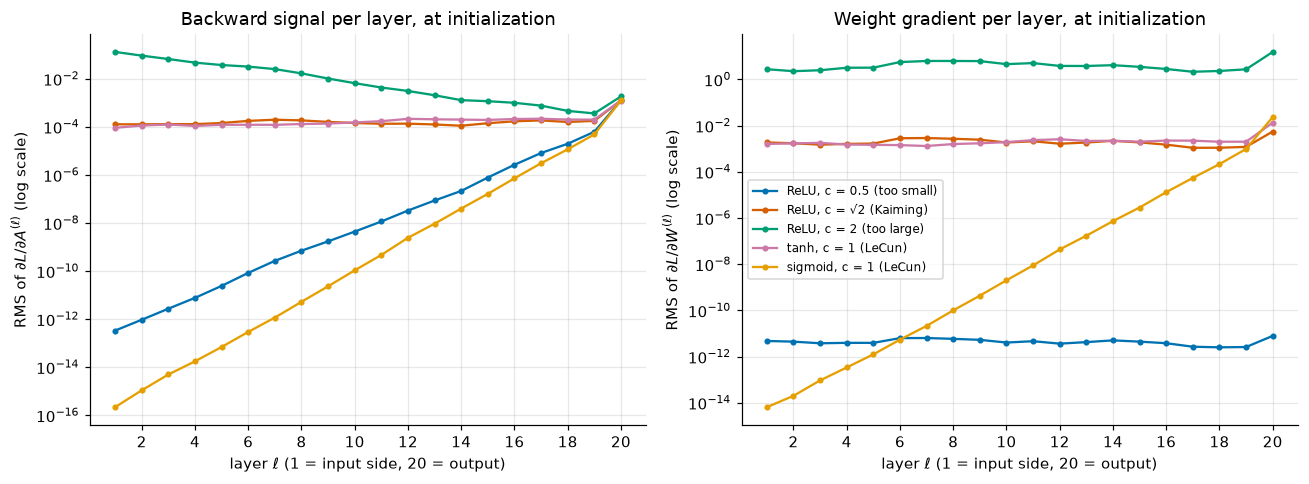

ReLU, c = 0.5 (too small) : dL/dA RMS at layer 20 0.0012, layer 1 / layer 20 = 2.67e-10;  dL/dW RMS ranges 2.5e-12 to 7.9e-12 (layers 2-20)
ReLU, c = √2 (Kaiming)    : dL/dA RMS at layer 20 0.0013, layer 1 / layer 20 = 0.101;  dL/dW RMS ranges 0.0011 to 0.0055 (layers 2-20)
ReLU, c = 2 (too large)   : dL/dA RMS at layer 20 0.0018, layer 1 / layer 20 = 71.2;  dL/dW RMS ranges 2.1 to 15 (layers 2-20)
tanh, c = 1 (LeCun)       : dL/dA RMS at layer 20 0.0012, layer 1 / layer 20 = 0.0732;  dL/dW RMS ranges 0.0013 to 0.013 (layers 2-20)
sigmoid, c = 1 (LeCun)    : dL/dA RMS at layer 20 0.0013, layer 1 / layer 20 = 1.73e-13;  dL/dW RMS ranges 2e-14 to 0.023 (layers 2-20)


In [19]:
def gradient_flow(act, c, depth=20, width=64, seed=0):
    """One backward pass at initialization. Returns (RMS of dL/dA per layer, RMS of dL/dW per layer), input layer first."""
    set_seed(seed)
    net = init_scaled_(make_mlp(depth, width, act), c)
    g_a = {}
    handles = [layer.register_full_backward_hook(
                   lambda mod, grad_in, grad_out, i=i: g_a.__setitem__(i, grad_out[0].pow(2).mean().sqrt().item()))
               for i, layer in enumerate(linears(net))]
    with warnings.catch_warnings():   # the first layer's input does not require grad; PyTorch warns, harmlessly
        warnings.simplefilter("ignore", UserWarning)
        F.cross_entropy(net(X_sp), y_sp).backward()
    for hd in handles:
        hd.remove()
    return [g_a[i] for i in range(depth)], [layer.weight.grad.pow(2).mean().sqrt().item() for layer in linears(net)]


configs = [("ReLU, c = 0.5 (too small)", nn.ReLU, 0.5), ("ReLU, c = √2 (Kaiming)", nn.ReLU, math.sqrt(2)),
           ("ReLU, c = 2 (too large)", nn.ReLU, 2.0), ("tanh, c = 1 (LeCun)", nn.Tanh, 1.0),
           ("sigmoid, c = 1 (LeCun)", nn.Sigmoid, 1.0)]
flow = {name: gradient_flow(act, c) for name, act, c in configs}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for k, (name, (ga, gw)) in enumerate(flow.items()):
    axes[0].semilogy(range(1, 21), ga, "o-", ms=3, color=COLORS[k], label=name)
    axes[1].semilogy(range(1, 21), gw, "o-", ms=3, color=COLORS[k], label=name)
axes[0].set_ylabel("RMS of $\\partial L/\\partial A^{(\\ell)}$ (log scale)")
axes[0].set_title("Backward signal per layer, at initialization")
axes[1].set_ylabel("RMS of $\\partial L/\\partial W^{(\\ell)}$ (log scale)")
axes[1].set_title("Weight gradient per layer, at initialization")
for ax in axes:
    ax.set_xlabel("layer $\\ell$ (1 = input side, 20 = output)")
    ax.set_xticks(range(2, 21, 2))
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
for name, (ga, gw) in flow.items():
    print(f"{name:26s}: dL/dA RMS at layer 20 {ga[-1]:.2g}, layer 1 / layer 20 = {ga[0] / ga[-1]:.3g};  dL/dW RMS ranges {min(gw[1:]):.2g} to {max(gw[1:]):.2g} (layers 2-20)")

Read the left panel from right to left, the direction the backward pass travels. The backward signal starts at the output (layer 20) with RMS about $10^{-3}$ in every network: for cross-entropy, $\partial L/\partial Z = (\hat P - Y)/N$ (notebook 10), whose entries are about $\pm 0.5/400$ when the predictions are near 50/50, whatever the weights. Then:

- **ReLU, Kaiming:** one drop by about $10\times$ from layer 20 to layer 19, then flat. The drop is the fan-out mismatch of Section 3 at the output layer, which has $n_\text{out} = 2$ and $n_\text{in} = 64$: its backward variance factor is $n_\text{out}\sigma_w^2\cdot\frac12 = 2 \cdot \frac{2}{64}\cdot\frac12 = \frac1{32}$, an RMS factor of about $0.18$. It happens once and does not compound.
- **ReLU, too small / too large:** shrinks or grows geometrically toward the input, by $c/\sqrt 2$ per layer as Section 3 predicts ($0.35$ and $1.41$).
- **tanh, LeCun:** the same single drop, then flat; near 0, $\tanh' \approx 1$.
- **sigmoid:** collapses by about 13 orders of magnitude.

**The right panel holds a surprise.** For the ReLU networks, the weight gradients are nearly **flat across layers** even for the bad scales — just uniformly tiny ($c = 0.5$: about $10^{-11}$) or uniformly huge ($c = 2$: about 10). The reason: $\partial L/\partial W^{(\ell)} = G_{A^{(\ell)}}^\top H^{(\ell-1)}$. With per-layer factor $k = c/\sqrt 2$, the backward signal at layer $\ell$ has been multiplied by $k$ about $L - \ell$ times, and the activation $H^{(\ell-1)}$ by $k$ about $\ell - 1$ times; the product scales like $k^{L-1}$, **the same for every layer**. So in a ReLU network a bad scale does not show up as "the early layers do not learn", but as **all** gradients being off by roughly $k^{L-1}$ — with $c = 0.5$ and $L = 20$, a factor of about $10^{-9}$ that no sensible learning rate can compensate. The practical lesson for diagnostics: a weight-gradient profile that is flat across layers is **not** evidence of healthy gradient flow — the $c = 0.5$ network is a counterexample — so look at the absolute size too, and at the backward signal $G_A$.

**Sigmoid is different, and it is the classic vanishing gradient.** Its outputs are not centered: $\sigma(a) \approx \frac12$, so $\mathbb E[h^2] \ge \frac14$ in every layer and the forward activations do not shrink. But on the backward pass each layer multiplies by $\sigma'(a) \le \frac14$ (notebook 16), and with $n\sigma_w^2 = 1$ the variance factor is $\mathbb E[\sigma'(a)^2] \le \frac1{16}$, so the RMS falls by at least $4\times$ per layer. Since the activations do not compensate, the weight gradients of the early layers really are smaller than those of the late layers — by about 12 orders of magnitude here. The first layers of a deep sigmoid network do not learn. This is a main reason deep networks moved from sigmoid to tanh and then to ReLU (Glorot, Bordes and Bengio, 2011).

### Checkpoint 4.1

From `flow["sigmoid, c = 1 (LeCun)"]`, compute `sigmoid_layer_factor`: the **geometric mean** of the ratios $\text{RMS}(G_{A^{(\ell)}}) / \text{RMS}(G_{A^{(\ell+1)}})$ over $\ell = 1, \dots, 19$ — the typical factor by which one sigmoid layer multiplies the backward signal. Compare it with the bound $\frac14$.

<details>
<summary><b>💡 Hint</b></summary>

The 19 ratios telescope: their product is $\text{RMS}(G_{A^{(1)}}) / \text{RMS}(G_{A^{(20)}})$, so the geometric mean is that ratio to the power $1/19$.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"sigmoid_layer_factor = {sigmoid_layer_factor:.4f}  (bound: 0.25)")

In [ ]:
_ga_ref = flow["sigmoid, c = 1 (LeCun)"][0]
_ratios = torch.tensor([_ga_ref[i] / _ga_ref[i + 1] for i in range(19)], dtype=f64)
check_close(sigmoid_layer_factor, _ratios.log().mean().exp().item(), "sigmoid_layer_factor", rtol=1e-6)
check(sigmoid_layer_factor < 0.25, "one sigmoid layer should shrink the backward signal by at least 4x")
passed("Checkpoint 4.1")

The measured factor is below $\frac14$: the bound $\sigma' \le \frac14$ is reached only at $a = 0$, and the pre-activations spread around 0, where $\sigma'$ is smaller.

## 5. What PyTorch does by default

So far we always overwrote the weights. What does `nn.Linear` do if we don't? Its initialization code, printed from the installed PyTorch:

In [22]:
print(f"torch {torch.__version__}")
print(inspect.getsource(nn.Linear.reset_parameters))

torch 2.14.1
    def reset_parameters(self) -> None:
        """
        Resets parameters based on their initialization used in ``__init__``.
        """
        # Setting a=sqrt(5) in kaiming_uniform is the same as initializing with
        # uniform(-1/sqrt(in_features), 1/sqrt(in_features)). For details, see
        # https://github.com/pytorch/pytorch/issues/57109
        init.kaiming_uniform_(self.weight, a=math.sqrt(5))
        if self.bias is not None:
            fan_in, _ = init._calculate_fan_in_and_fan_out(self.weight)
            bound = 1 / math.sqrt(fan_in) if fan_in > 0 else 0
            init.uniform_(self.bias, -bound, bound)



`kaiming_uniform_` with `a = √5` treats the layer as if it were followed by a Leaky ReLU with negative slope $\sqrt 5$ (Section 3), whose gain is $\sqrt{2/(1 + 5)} = 1/\sqrt 3$. So

$$\sigma_w = \frac{\text{gain}}{\sqrt{n_\text{in}}} = \frac{1}{\sqrt{3\,n_\text{in}}}, \qquad \text{bound} = \sqrt 3\,\sigma_w = \frac{1}{\sqrt{n_\text{in}}}:$$

the weights are $U(-1/\sqrt{n_\text{in}}, 1/\sqrt{n_\text{in}})$, and so are the biases. As the comment says, the strange-looking `a` is just a way to reproduce this older rule, inherited from the Lua Torch library (see the linked GitHub issue). Empirically:

In [23]:
torch.manual_seed(0)
layer = nn.Linear(256, 512)
fi = layer.weight.shape[1]
print(f"weight: std {layer.weight.std().item():.5f}  vs 1/√(3·{fi}) = {1 / math.sqrt(3 * fi):.5f};  "
      f"max |w| {layer.weight.abs().max().item():.5f} vs 1/√{fi} = {1 / math.sqrt(fi):.5f}")
print(f"bias  : std {layer.bias.std().item():.5f}  vs 1/√(3·{fi}) = {1 / math.sqrt(3 * fi):.5f};  "
      f"max |b| {layer.bias.abs().max().item():.5f} vs 1/√{fi} = {1 / math.sqrt(fi):.5f}")

weight: std 0.03605  vs 1/√(3·256) = 0.03608;  max |w| 0.06250 vs 1/√256 = 0.06250
bias  : std 0.03744  vs 1/√(3·256) = 0.03608;  max |b| 0.06211 vs 1/√256 = 0.06250


**Consequence for deep ReLU networks.** The default variance $\sigma_w^2 = 1/(3n)$ is **one sixth** of Kaiming's $2/n$. With ReLU, each layer multiplies the weight part of the variance by $\frac12 n \sigma_w^2 = \frac16$. But the default biases are random too, with variance $\text{bound}^2/3 = 1/(3n)$, independent of everything else, so they add to the pre-activation variance:

$$v_\ell = \tfrac16\,v_{\ell-1} + \tfrac{1}{3n}.$$

This recursion does not go to 0. It converges to the fixed point $v^* = \frac16 v^* + \frac{1}{3n}$, i.e. $v^* = \frac{2}{5n}$. So the pre-activations settle at standard deviation $\sqrt{2/(5n)}$ — but that variance comes almost entirely from the **biases**, which are the same for every example. The part of $A^{(\ell)}$ that depends on the input shrinks layer after layer (heuristically by $\sqrt{1/6} \approx 0.41$ in standard deviation: the weights multiply its variance by $n\sigma_w^2 = \frac13$ and the ReLU keeps about half). To see both effects, we measure two standard deviations of $A^{(\ell)}$: over all entries, and **across examples** (the standard deviation of each unit over the batch, averaged over units).

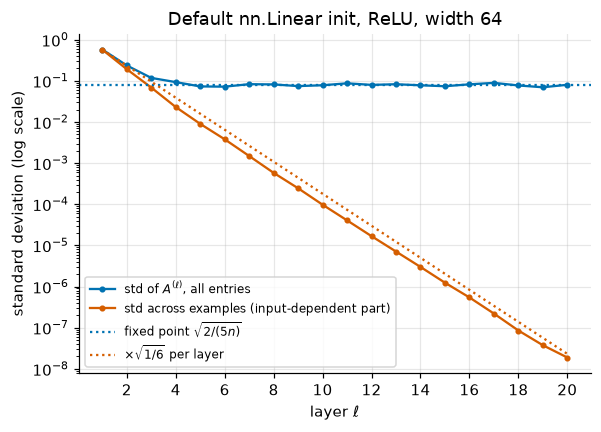

total std at layer 20: 0.0802  vs fixed point √(2/(5·64)) = 0.0791
across-example std: layer 1 0.572, layer 20 1.89e-08;  average factor per layer 0.404 vs √(1/6) = 0.408


In [24]:
def default_stack_stats(width, depth=20, n_examples=1000, seed=0):
    """Deep ReLU stack of default-initialized nn.Linear layers. Per layer: (total std of A, mean across-example std of A)."""
    torch.manual_seed(seed)
    h = torch.randn(n_examples, width)                     # (N, width)
    total, across = [], []
    with torch.no_grad():
        for _ in range(depth):
            a = nn.Linear(width, width)(h)                 # (N, width)
            total.append(a.std().item())
            across.append(a.std(dim=0).mean().item())      # std over examples, per unit, then averaged
            h = torch.relu(a)
    return total, across


total64, across64 = default_stack_stats(64)
layers_ = range(1, 21)
plt.semilogy(layers_, total64, "o-", ms=3, color=COLORS[0], label="std of $A^{(\\ell)}$, all entries")
plt.semilogy(layers_, across64, "o-", ms=3, color=COLORS[1], label="std across examples (input-dependent part)")
plt.axhline(math.sqrt(2 / (5 * 64)), color=COLORS[0], ls=":", label="fixed point $\\sqrt{2/(5n)}$")
plt.semilogy(layers_, [across64[0] * (1 / 6) ** ((l - 1) / 2) for l in layers_], ":", color=COLORS[1], label="$\\times\\sqrt{1/6}$ per layer")
plt.xticks(range(2, 21, 2))
plt.xlabel("layer $\\ell$")
plt.ylabel("standard deviation (log scale)")
plt.title("Default nn.Linear init, ReLU, width 64")
plt.legend(fontsize=8)
plt.show()
per_layer = (across64[-1] / across64[0]) ** (1 / 19)
print(f"total std at layer 20: {total64[-1]:.4f}  vs fixed point √(2/(5·64)) = {math.sqrt(2 / 320):.4f}")
print(f"across-example std: layer 1 {across64[0]:.3g}, layer 20 {across64[-1]:.3g};  average factor per layer {per_layer:.3f} vs √(1/6) = {math.sqrt(1 / 6):.3f}")

The total standard deviation drops to the predicted fixed point within a few layers and stays there, but the input-dependent part falls by about $0.4$ per layer, to around $10^{-8}$ of its starting value after 20 layers. A deep, default-initialized ReLU network therefore produces **nearly the same output for every input**: the information about the input is drowned by the biases. This is why the 16-layer default network in the next section cannot get off the ground.

The default is not a bug for every model: it is reasonable for shallow networks, and normalization layers (notebook 24) remove most of the sensitivity. But for a deep plain MLP, you should choose the initialization yourself.

### Checkpoint 5.1

For a deep ReLU stack of default-initialized `nn.Linear(128, 128)` layers, compute by hand `default_fixed_std`: the standard deviation the pre-activations settle at. The check runs the stack.

<details>
<summary><b>💡 Hint</b></summary>

$v^* = 2/(5n)$ with $n = 128$; take the square root.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"default_fixed_std = {default_fixed_std:.5f}")

In [ ]:
_total, _ = default_stack_stats(128)
print(f"measured total std, layers 15-20: {[round(v, 4) for v in _total[14:]]}")
check_close(default_fixed_std, math.sqrt(2 / 640), "default_fixed_std", rtol=1e-6)
check(abs(sum(_total[14:]) / 6 / default_fixed_std - 1) < 0.1, "the deep layers should settle near your value")
passed("Checkpoint 5.1")

## 6. Training consequences

Back to the motivating problem, now with four initializations and three seeds each: a 16-layer ReLU MLP (15 hidden layers of 32 units) on the spirals, full-batch SGD with learning rate 0.05 for 1500 steps.

- **default**: `nn.Linear`'s own initialization (Section 5);
- **too small**: $c = 0.5$, i.e. weights $\mathcal N(0, 0.25/n_\text{in})$, zero biases;
- **Kaiming**: $c = \sqrt 2$;
- **too large**: $c = 2$.

(The spiral inputs have standard deviation about $0.43$ rather than 1, so even Kaiming's first layer starts smaller than 1. That is a constant factor, not one that compounds with depth.)

In [27]:
init_choices = {"default": None, "too small (c = 0.5)": 0.5, "Kaiming (c = √2)": math.sqrt(2), "too large (c = 2)": 2.0}
runs, final_models = {}, {}
for name, c in init_choices.items():
    runs[name] = []
    for seed in range(3):
        set_seed(seed)
        net = make_mlp(depth=16, width=32)
        if c is not None:
            init_scaled_(net, c)
        runs[name].append(train_full_batch(net, X_sp, y_sp, steps=1500, lr=0.05))
        if seed == 0:
            final_models[name] = net

for name, curves in runs.items():
    finals = ", ".join(f"{cv[-1]:.3g}" for cv in curves)
    print(f"{name:20s}: initial loss {', '.join(f'{cv[0]:.3g}' for cv in curves):24s} final loss {finals}")
for s, cv in enumerate(runs["too large (c = 2)"]):
    first_bad = next((t for t, v in enumerate(cv) if not math.isfinite(v)), None)
    print(f"too large, seed {s}: largest finite loss {max(v for v in cv if math.isfinite(v)):.3g}, first non-finite loss at step {first_bad}")

default             : initial loss 0.702, 0.693, 0.693      final loss 0.693, 0.693, 0.693
too small (c = 0.5) : initial loss 0.693, 0.693, 0.693      final loss 0.693, 0.693, 0.693
Kaiming (c = √2)    : initial loss 0.695, 0.74, 0.697       final loss 0.000117, 8.76e-05, 0.000123
too large (c = 2)   : initial loss 10.7, 66.1, 19.3         final loss nan, nan, nan
too large, seed 0: largest finite loss 1.24e+07, first non-finite loss at step 3
too large, seed 1: largest finite loss 7.27e+33, first non-finite loss at step 3
too large, seed 2: largest finite loss 1.12e+13, first non-finite loss at step 4


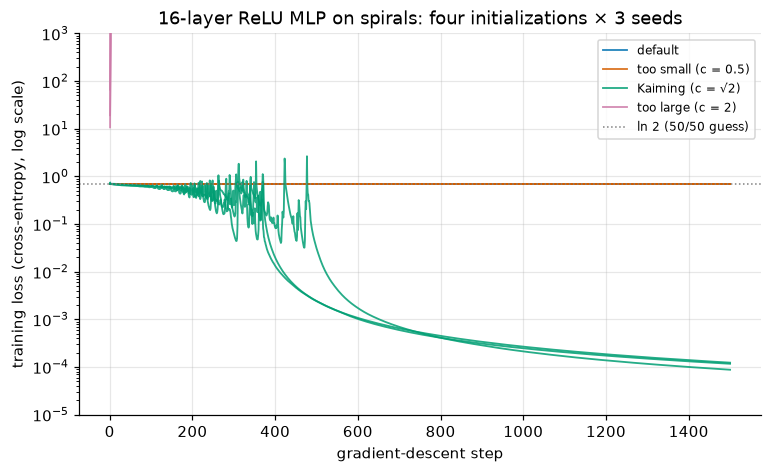

In [28]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for k, (name, curves) in enumerate(runs.items()):
    for s, cv in enumerate(curves):
        ax.semilogy(range(1, 1501), cv, color=COLORS[k], alpha=0.85, lw=1.2, label=name if s == 0 else None)
ax.axhline(math.log(2), color="gray", ls=":", lw=1, label="ln 2 (50/50 guess)")
ax.set_ylim(1e-5, 1e3)                     # the too-large runs leave the top of the plot within a few steps
ax.set_xlabel("gradient-descent step")
ax.set_ylabel("training loss (cross-entropy, log scale)")
ax.set_title("16-layer ReLU MLP on spirals: four initializations × 3 seeds")
ax.legend(fontsize=8)
plt.show()

Three distinct outcomes, consistent across seeds:

- **default** and **too small** sit at $\ln 2$ for all 1500 steps (the default curves are hidden under the too-small ones). Their outputs barely depend on the input (Section 5), and their gradients are tiny (Section 4).
- **Kaiming** goes through a noisy phase between roughly steps 200 and 480, then drops steadily, ending near $10^{-4}$ — more than three orders of magnitude below $\ln 2$ — for all three seeds.
- **too large** starts with an enormous loss (10 to 66: the logits are huge), the first few gradient steps blow it up further (to between $10^{7}$ and $10^{34}$), and by step 3 or 4 it is `nan`. Those curves leave the top of the plot immediately. A smaller learning rate might avoid the `nan` in principle, but the gradients are of order $k^{L-1}$ with $k = \sqrt 2$, about $200$, so the learning rate would have to shrink accordingly.

The decision boundaries of the seed-0 runs make the difference concrete:

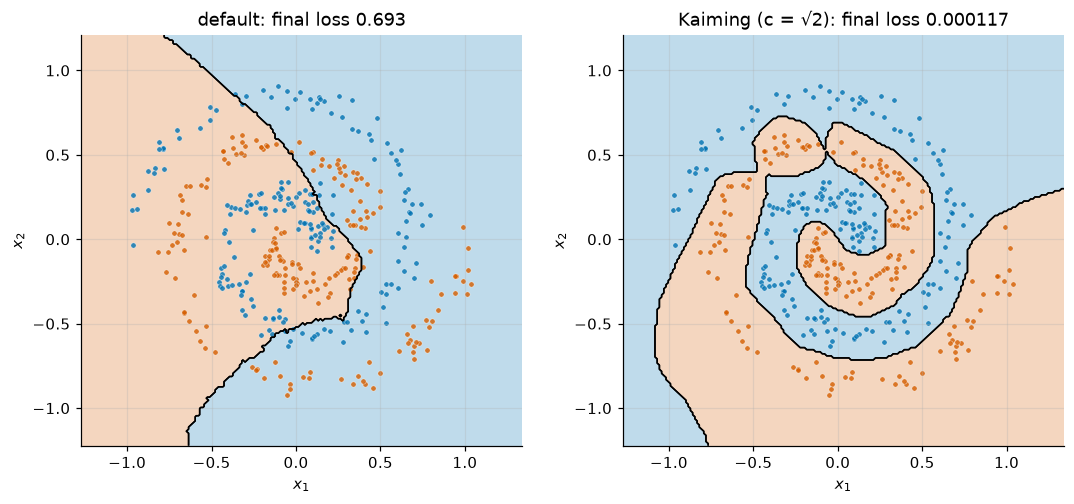

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, name in zip(axes, ["default", "Kaiming (c = √2)"]):
    net = final_models[name]
    plot_decision_boundary(lambda P, net=net: net(P).argmax(dim=1), X_sp, y_sp, ax=ax,
                           title=f"{name}: final loss {runs[name][0][-1]:.3g}")
plt.tight_layout()
plt.show()

The default network's boundary is a single smooth curve that cuts the plane roughly in half and ignores the spiral structure: its two logits differ by tiny amounts (the loss is still $\ln 2$ to three digits), and `argmax` turns those tiny differences into a boundary. The Kaiming network follows both arms of the spiral.

**What this does and does not show.** The scale of the initial weights alone decided between "trains" and "does not train" for this deep, narrow, plain MLP and this optimizer. Shallower networks are much less sensitive (Exercise 4 measures how the trainable depth depends on the initialization). Modern architectures add two tools that make networks far less sensitive to the initial scale: **normalization layers**, which rescale activations to a fixed variance at every layer, and **residual connections**, which give gradients a path around each layer. Both are the subject of notebook 24. Adaptive optimizers (notebook 19) also rescale each parameter's update, which helps with uniformly tiny gradients but not with an input signal that has already been destroyed.

## 7. Orthogonal initialization

A random Gaussian matrix with $\sigma_w^2 = 1/n$ preserves the norm of a vector only **on average**; each draw stretches some directions and shrinks others, and in a deep stack these fluctuations accumulate (the wandering Kaiming curve of Section 2). An **orthogonal** matrix $Q$, with $Q^\top Q = I$, preserves norms **exactly**: $\|Q\mathbf x\|^2 = \mathbf x^\top Q^\top Q\,\mathbf x = \|\mathbf x\|^2$. A product of orthogonal matrices is orthogonal ($(Q_1Q_2)^\top Q_1 Q_2 = Q_2^\top Q_2 = I$), so a deep **linear** stack of orthogonal layers preserves every input's norm exactly, at every depth. Saxe, McClelland and Ganguli (2014) analyzed deep linear networks and proposed this initialization; PyTorch provides `nn.init.orthogonal_(w, gain)`.

We compare 100 linear layers of width 64, Gaussian with $\sigma_w^2 = 1/64$ versus orthogonal, on 500 random inputs: the ratio $\|\text{output}\| / \|\text{input}\|$ for each input, and the singular values of the product of all 100 matrices (how much it stretches each direction).

In [30]:
torch.manual_seed(0)
n_o, depth_o = 64, 100
x_o = torch.randn(500, n_o, dtype=f64)                     # (500, 64)
for name in ["Gaussian N(0, 1/n)", "orthogonal"]:
    P = torch.eye(n_o, dtype=f64)                          # running product W^(L) ... W^(1)
    for _ in range(depth_o):
        W = torch.empty(n_o, n_o, dtype=f64)
        if name == "orthogonal":
            nn.init.orthogonal_(W)
        else:
            nn.init.normal_(W, 0.0, 1 / math.sqrt(n_o))
        P = W @ P
    ratio = (x_o @ P.T).norm(dim=1) / x_o.norm(dim=1)      # (500,)
    sv = torch.linalg.svdvals(P)
    print(f"{name:20s}: ‖out‖/‖in‖ from {ratio.min().item():.3g} to {ratio.max().item():.3g};  "
          f"singular values of the product from {sv.min().item():.3g} to {sv.max().item():.3g}")

Gaussian N(0, 1/n)  : ‖out‖/‖in‖ from 0.0218 to 1.93;  singular values of the product from 2.14e-18 to 4.96
orthogonal          : ‖out‖/‖in‖ from 1 to 1;  singular values of the product from 1 to 1


The orthogonal stack preserves every norm to `float64` rounding, and all 64 singular values of the 100-layer product are exactly 1. The Gaussian stack, although correct "on average", has singular values spread over many orders of magnitude: a few directions are amplified and most are crushed, so the output norm depends strongly on the input direction.

With nonlinearities the guarantee is no longer exact: a ReLU zeroes about half the coordinates, so one uses `gain = √2` to restore the scale on average, and the norm then fluctuates again. Orthogonal initialization is most useful for deep linear-ish paths and for recurrent networks, where the same matrix is applied many times (Chapter 8).

### Checkpoint 7.1

Build your own orthogonal matrix. Write `my_orthogonal(n, seed)`: draw an $n \times n$ standard-normal matrix with `torch.Generator().manual_seed(seed)` in `float64`, compute its QR decomposition with `torch.linalg.qr`, and return $Q$ with each column multiplied by the sign of the corresponding diagonal entry of $R$. (The sign fix makes the result uniformly distributed over orthogonal matrices, which is what `nn.init.orthogonal_` also does; the check only tests orthogonality.)

<details>
<summary><b>💡 Hint</b></summary>

`Q, R = torch.linalg.qr(A)`, then `Q * torch.sign(torch.diagonal(R))` — the `(n,)` sign vector broadcasts across rows, so it scales each column.

</details>

In [ ]:
def my_orthogonal(n, seed):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
_Q = my_orthogonal(32, seed=3)
check_shape(_Q, (32, 32), "my_orthogonal(32, 3)")
check_close(_Q.T @ _Q, torch.eye(32, dtype=f64), "QᵀQ", atol=1e-10)
_A = torch.randn(32, 32, generator=torch.Generator().manual_seed(3), dtype=f64)
_Qr, _Rr = torch.linalg.qr(_A)
check_close(_Q, _Qr * torch.sign(torch.diagonal(_Rr)), "my_orthogonal", atol=1e-10)
_v = torch.randn(10, 32, dtype=f64)
check_close((_v @ _Q.T).norm(dim=1), _v.norm(dim=1), "norms after multiplying by Q", atol=1e-10)
check_close(my_orthogonal(1, seed=0), torch.ones(1, 1, dtype=f64), "my_orthogonal(1, 0): the sign fix makes a 1x1 result exactly +1")
passed("Checkpoint 7.1")

## Exercises

### Exercise 1 (modify): which scale keeps tanh activations stable?

The cell below runs the 50-layer simulation of Section 2 (`propagate`, width 256) for a list of scales $c$, plots the standard deviation of the activations per layer, and prints, at layer 50, the standard deviation and the fraction of **saturated** units ($|h| > 0.99$ for tanh; for ReLU this column is just the fraction above 0.99).

1. Run it as given (ReLU).
2. Change `ACT` to `torch.tanh`. Which scale now keeps the standard deviation constant? Is any of them as clean as Kaiming was for ReLU?
3. For $c = 1$ the standard deviation decays slowly instead of geometrically. Explain why, and predict its value at layer 50 using $\tanh(a) \approx a - a^3/3$ and $\mathbb E[a^4] = 3v^2$ for a normal $a$ with variance $v$.
4. What goes wrong for large $c$, even though the standard deviation stays bounded? Relate it to Section 4.

<details>
<summary><b>💡 Hint</b></summary>

For small $v$: $\tanh(a)^2 \approx a^2 - \frac23 a^4$, so with $n\sigma_w^2 = 1$ the variance follows $v_{\ell+1} \approx v_\ell - 2v_\ell^2$. Try the guess $v_\ell \approx \alpha/\ell$ for large $\ell$ (compare $v_{\ell+1} - v_\ell$ with $-2v_\ell^2$). For large $c$, look at $\tanh'$ where $|h| > 0.99$.

</details>

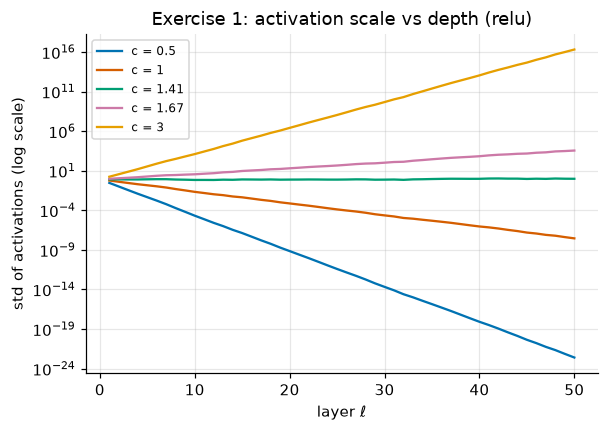

c = 0.500: std at layer 50 = 2.55e-23, fraction |h| > 0.99 = 0.0%
c = 1.000: std at layer 50 = 1.52e-08, fraction |h| > 0.99 = 0.0%
c = 1.414: std at layer 50 = 0.37, fraction |h| > 0.99 = 6.3%
c = 1.667: std at layer 50 = 1.91e+03, fraction |h| > 0.99 = 49.8%
c = 3.000: std at layer 50 = 1.2e+16, fraction |h| > 0.99 = 50.1%


In [33]:
ACT = torch.relu
SCALES = [0.5, 1.0, math.sqrt(2), 5 / 3, 3.0]

for k, c in enumerate(SCALES):
    s = propagate(ACT, c)
    plt.semilogy(range(1, 51), s, color=COLORS[k], label=f"c = {c:.3g}")
plt.xlabel("layer $\\ell$")
plt.ylabel("std of activations (log scale)")
plt.title(f"Exercise 1: activation scale vs depth ({getattr(ACT, '__name__', 'act')})")
plt.legend(fontsize=8)
plt.show()

gen_ex = torch.Generator().manual_seed(0)
for c in SCALES:
    h = torch.randn(1000, 256, generator=gen_ex)
    for _ in range(50):
        h = ACT(h @ (torch.randn(256, 256, generator=gen_ex) * c / 16).T)
    print(f"c = {c:.3f}: std at layer 50 = {h.std().item():.3g}, fraction |h| > 0.99 = {(h.abs() > 0.99).float().mean().item():.1%}")

*Your answer:*

### Exercise 2 (implement): the standard deviation `nn.init` uses

Write `init_std(fan_in, fan_out, scheme, nonlinearity="linear", mode="fan_in", negative_slope=0.0)` that returns the standard deviation of the weights that `torch.nn.init` produces, **without calling anything from `nn.init`** (including `calculate_gain`):

- `scheme="xavier"`: $\text{gain}\cdot\sqrt{2/(n_\text{in} + n_\text{out})}$ (`mode` is ignored);
- `scheme="kaiming"`: $\text{gain}/\sqrt{\text{fan}}$ with $\text{fan} = n_\text{in}$ or $n_\text{out}$ according to `mode`;
- gains: `"linear"` and `"sigmoid"`: 1; `"tanh"`: $5/3$; `"relu"`: $\sqrt 2$; `"leaky_relu"`: $\sqrt{2/(1 + s^2)}$ with $s$ = `negative_slope`.

Also write `uniform_bound(std)`, the bound $a$ of a uniform $U(-a, a)$ with that standard deviation. The check compares your values with tensors generated by `nn.init` (all four of `xavier_normal_`, `xavier_uniform_`, `kaiming_normal_`, `kaiming_uniform_`) for several shapes and settings.

<details>
<summary><b>💡 Hint</b></summary>

Compute the gain first with a small dictionary or `if` chain, then the fan. `uniform_bound(std)` is `math.sqrt(3) * std`. Note that `kaiming_*` in PyTorch takes the slope as its `a` argument, and Xavier takes the gain directly.

</details>

In [ ]:
def init_std(fan_in, fan_out, scheme, nonlinearity="linear", mode="fan_in", negative_slope=0.0):
    # YOUR CODE HERE
    raise NotImplementedError


def uniform_bound(std):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
_cases = [((400, 100), "kaiming", "relu", "fan_in", 0.0), ((400, 100), "kaiming", "relu", "fan_out", 0.0),
          ((120, 250), "kaiming", "leaky_relu", "fan_in", 0.2), ((120, 250), "kaiming", "tanh", "fan_out", 0.0),
          ((300, 100), "xavier", "tanh", "fan_in", 0.0), ((80, 500), "xavier", "linear", "fan_in", 0.0),
          ((80, 500), "xavier", "sigmoid", "fan_in", 0.0)]
_orig = {k: getattr(nn.init, k) for k in ["calculate_gain", "xavier_normal_", "xavier_uniform_", "kaiming_normal_", "kaiming_uniform_"]}
_blocked = lambda *a, **k: (_ for _ in ()).throw(AssertionError("init_std must not call torch.nn.init"))
try:
    for _k in _orig:
        setattr(nn.init, _k, _blocked)
    _mine = [(init_std(sh[1], sh[0], sc, nl, md, sl), sh, sc, nl, md, sl) for sh, sc, nl, md, sl in _cases]
    _bounds = [uniform_bound(s) for s, *_ in _mine]
    # deterministic edge cases: exact formulas, square layers, slope 0, fan_in = 1
    _exact = [(init_std(100, 300, "kaiming", "relu"), math.sqrt(2 / 100)),
              (init_std(100, 300, "kaiming", "relu", mode="fan_out"), math.sqrt(2 / 300)),
              (init_std(64, 64, "xavier"), 1 / 8),                                     # square: Xavier = LeCun
              (init_std(50, 20, "kaiming", "leaky_relu", negative_slope=0.0), init_std(50, 20, "kaiming", "relu")),
              (init_std(50, 20, "kaiming", "leaky_relu", negative_slope=1.0), init_std(50, 20, "kaiming", "linear")),
              (init_std(1, 10, "kaiming", "tanh"), 5 / 3),
              (uniform_bound(1.0), math.sqrt(3))]
finally:
    for _k, _f in _orig.items():
        setattr(nn.init, _k, _f)
for _i, (_got, _want) in enumerate(_exact):
    check_close(_got, _want, f"edge case {_i}", rtol=1e-9)
torch.manual_seed(0)
for (_s, _sh, _sc, _nl, _md, _sl), _b in zip(_mine, _bounds):
    _g = nn.init.calculate_gain(_nl, _sl if _nl == "leaky_relu" else None)
    if _sc == "xavier":
        _wn = nn.init.xavier_normal_(torch.empty(_sh), gain=_g)
        _wu = nn.init.xavier_uniform_(torch.empty(_sh), gain=_g)
    else:
        _wn = nn.init.kaiming_normal_(torch.empty(_sh), a=_sl, mode=_md, nonlinearity=_nl)
        _wu = nn.init.kaiming_uniform_(torch.empty(_sh), a=_sl, mode=_md, nonlinearity=_nl)
    _label = f"{_sc}, {_nl}, {_md}, shape {_sh}"
    check(abs(_wn.std().item() / _s - 1) < 0.03, f"normal std for {_label}: nn.init gives {_wn.std().item():.4f}, you give {_s:.4f}")
    check(abs(_wu.std().item() / _s - 1) < 0.03, f"uniform std for {_label}: nn.init gives {_wu.std().item():.4f}, you give {_s:.4f}")
    check(_wu.abs().max().item() <= _b + 1e-6 and _wu.abs().max().item() > 0.99 * _b, f"uniform bound for {_label}")
passed("Exercise 2")

### Exercise 3 (debug): a He initializer that works only for square layers

`he_init_(model)` is meant to apply Kaiming normal initialization (fan-in mode, ReLU gain) to every `nn.Linear` of a model and zero the biases. A colleague tested it on an MLP whose hidden layers are all 64 × 64 and saw the per-layer activation scale stay flat, as expected. On other models it misbehaves. The buggy line is shown in the comment; find the problem and write the fix.

The test, `test_he_init(init_fn, model)`, initializes `model` with `init_fn` and checks every layer's weight standard deviation against $\sqrt{2/n_\text{in}}$ and that the biases are exactly 0. Below it, `he_init_buggy_` is the colleague's original code, kept for comparison.

In [36]:
def test_he_init(init_fn, model, seed=0):
    """Initialize `model` with `init_fn`; raise AssertionError unless every nn.Linear has weight std ≈ √(2/in_features) and zero bias."""
    torch.manual_seed(seed)
    init_fn(model)
    for i, lin in enumerate(linears(model)):
        want, got = math.sqrt(2 / lin.in_features), lin.weight.std().item()
        check(abs(got / want - 1) < 0.15,
              f"layer {i} ({lin.in_features} -> {lin.out_features}): weight std {got:.4f}, expected √(2/fan_in) = {want:.4f}")
        check(lin.bias.abs().max().item() == 0.0, f"layer {i}: biases should be zero")


def he_init_buggy_(model):
    for m in model.modules():
        if isinstance(m, nn.Linear):
            fan_in = m.weight.shape[0]
            with torch.no_grad():
                m.weight.normal_(0.0, math.sqrt(2.0 / fan_in))
                m.bias.zero_()
    return model


def square_net():          # hidden layers all 64 x 64: the colleague's test model
    return nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 64))


def funnel_net():          # non-square layers, including the 2-input first layer and a 3-output last layer
    return nn.Sequential(nn.Linear(2, 512), nn.ReLU(), nn.Linear(512, 128), nn.ReLU(),
                         nn.Linear(128, 32), nn.ReLU(), nn.Linear(32, 3))


test_he_init(he_init_buggy_, square_net())
print("the buggy initializer PASSES the test on the all-square network (why the colleague missed it)")
try:
    test_he_init(he_init_buggy_, funnel_net())
    print("the buggy initializer passes on the funnel network")
except AssertionError as err:
    print(f"the buggy initializer FAILS on the non-square network: {err}")

the buggy initializer PASSES the test on the all-square network (why the colleague missed it)
the buggy initializer FAILS on the non-square network: layer 0 (2 -> 512): weight std 0.0642, expected √(2/fan_in) = 1.0000


<details>
<summary><b>💡 Hint</b></summary>

What is the shape of `nn.Linear(n_in, n_out).weight`? For a square layer, which mistake would be invisible? The demonstration after the check uses a "funnel" network whose widths shrink.

</details>

In [ ]:
def he_init_(model):
    for m in model.modules():
        if isinstance(m, nn.Linear):
            # Buggy version:
            #     fan_in = m.weight.shape[0]
            # YOUR CODE HERE
            raise NotImplementedError
            with torch.no_grad():
                m.weight.normal_(0.0, math.sqrt(2.0 / fan_in))
                m.bias.zero_()
    return model

In [ ]:
test_he_init(he_init_, funnel_net())                 # non-square layers: the case the bug breaks
test_he_init(he_init_, square_net())                 # square layers must still work
test_he_init(he_init_, nn.Sequential(nn.Linear(300, 7)))   # a single, very non-square layer (fan_in 300, fan_out 7)
passed("Exercise 3")

The effect of the bug, on a funnel network 256 → 512 → 256 → 128 → 64 → 32 → 16 (ReLU), shown by the per-layer activation scale with the buggy and the fixed fan:

In [39]:
def he_init_with_dim_(model, dim):
    with torch.no_grad():
        for m in linears(model):
            m.weight.normal_(0.0, math.sqrt(2.0 / m.weight.shape[dim]))
            m.bias.zero_()
    return model


funnel_widths = [256, 512, 256, 128, 64, 32, 16]
x_f = torch.randn(1000, 256)
for dim, label in [(0, "buggy (shape[0] = fan_out)"), (1, "fixed (shape[1] = fan_in) ")]:
    torch.manual_seed(0)
    layers_f = []
    for a, b in zip(funnel_widths[:-1], funnel_widths[1:]):
        layers_f += [nn.Linear(a, b), nn.ReLU()]
    funnel = he_init_with_dim_(nn.Sequential(*layers_f), dim)
    h, stds = x_f, []
    with torch.no_grad():
        for mod in funnel:
            h = mod(h)
            if isinstance(mod, nn.ReLU):
                stds.append(h.std().item())
    print(f"{label}: activation std per layer {[round(s, 3) for s in stds]}")

buggy (shape[0] = fan_out): activation std per layer [0.586, 0.839, 1.213, 1.49, 2.063, 2.054]
fixed (shape[1] = fan_in) : activation std per layer [0.829, 0.839, 0.857, 0.745, 0.729, 0.514]


### Exercise 4 (investigate): how deep can each initialization go?

Section 6 compared initializations at one depth. Now vary the depth: for MLPs with $\{2, 5, 10, 20, 40\}$ linear layers (width 32, ReLU) on the spirals, train with full-batch SGD (learning rate 0.1, 800 steps) under three initializations — `nn.Linear`'s **default**, **LeCun** ($c = 1$, i.e. $\sigma_w^2 = 1/n_\text{in}$) and **Kaiming** ($c = \sqrt 2$) — with 3 seeds each, and plot the final training loss against depth.

Complete the experiment loop: for each initialization and depth, train 3 seeds (call `set_seed(seed)` before building each network with `make_mlp(depth=d, width=32)`; apply `init_scaled_(net, c)` unless `c` is `None`; train with `train_full_batch(net, X_sp, y_sp, steps=800, lr=0.1)`), and append the list of 3 final losses (computed after training, under `torch.no_grad()`) to `final_loss[name]`. The plotting code is given. The experiment takes about 30 seconds. Then answer:

1. For each initialization, up to which depth does training succeed within this budget? Where does each one break, and how consistent are the seeds?
2. Why do the shallowest networks fail too, whatever the initialization? Is that the same kind of failure?
3. Explain the order in which the initializations break, using Sections 2–5.

<details>
<summary><b>💡 Hint</b></summary>

A loss near $\ln 2 \approx 0.69$ means the network still predicts 50/50. For question 2, think about what one hidden layer of 32 units can represent and how fast gradient descent fits the spirals with it; for question 3, recall the per-layer variance factors: $\frac16$ (default, plus the bias floor), $\frac12$ (LeCun), 1 (Kaiming).

</details>

In [ ]:
depths = [2, 5, 10, 20, 40]
inits_ex = {"default": None, "LeCun (c = 1)": 1.0, "Kaiming (c = √2)": math.sqrt(2)}
final_loss = {name: [] for name in inits_ex}                      # name -> list over depths of [loss per seed]
# YOUR CODE HERE
raise NotImplementedError

fig, ax = plt.subplots(figsize=(7, 4.5))
for k, (name, rows) in enumerate(final_loss.items()):
    for j, d in enumerate(depths):
        ax.scatter([d * (1 + 0.04 * (k - 1))] * 3, rows[j], color=COLORS[k], s=18, alpha=0.8, label=name if j == 0 else None)
    ax.plot(depths, [sorted(r)[1] for r in rows], color=COLORS[k], lw=1)   # median over seeds
ax.axhline(math.log(2), color="gray", ls=":", lw=1, label="ln 2")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(depths, [str(d) for d in depths])
ax.minorticks_off()
ax.set_xlabel("depth (number of linear layers)")
ax.set_ylabel("final training loss (log scale)")
ax.set_title("Exercise 4: final loss vs depth, 3 seeds per point (line: median)")
ax.legend(fontsize=8)
plt.show()

A follow-up for question 3: rerun the deepest Kaiming network with a five times smaller learning rate (same 800 steps).

In [41]:
follow_up = []
for seed in range(3):
    set_seed(seed)
    net = init_scaled_(make_mlp(depth=40, width=32), math.sqrt(2))
    train_full_batch(net, X_sp, y_sp, steps=800, lr=0.02)
    with torch.no_grad():
        follow_up.append(F.cross_entropy(net(X_sp), y_sp).item())
print(f"Kaiming, depth 40, lr 0.02: final losses {[f'{v:.3g}' for v in follow_up]}")

Kaiming, depth 40, lr 0.02: final losses ['0.247', '0.0564', '0.391']


*Your conclusion:*

## Summary and what's next

- **Symmetry breaking.** Units with identical incoming weights, biases and outgoing weights receive identical gradients, so they stay identical forever (proved from the backward recursion, verified to the last bit). Weights must start random; biases can start at 0. All-zero weights are a fixed point: only the output bias can move.
- **Forward variance.** For $a = \sum_j w_j h_j$ with independent zero-mean weights, $\operatorname{Var}(a) = n_\text{in}\sigma_w^2\,\mathbb E[h^2]$. Keeping it constant across layers gives $\sigma_w^2 = 1/n_\text{in}$ for linear (and, to first order, tanh) layers (LeCun 1998), and $\sigma_w^2 = 2/n_\text{in}$ for ReLU (He et al. 2015), because $\mathbb E[\operatorname{relu}(a)^2] = \frac12\operatorname{Var}(a)$ for symmetric $a$. Any other constant compounds geometrically with depth.
- **Backward variance** gives the same rule with $n_\text{out}$; Glorot and Bengio (2010) compromise with $2/(n_\text{in} + n_\text{out})$. The fan-in/fan-out mismatch telescopes to a ratio of widths, so either mode works. Uniform $U(-a, a)$ with $a = \sqrt 3\,\sigma_w$ is equivalent to the normal at the level of variance. `nn.init` implements all of these, with activation **gains** ($\sqrt 2$ for ReLU, $\sqrt{2/(1+s^2)}$ for Leaky ReLU; tanh's $5/3$ is a convention); in `nn.Linear`'s `(out, in)` weight, the fan-in is `shape[1]`.
- **Gradient flow.** In ReLU networks a wrong scale multiplies *every* weight gradient by about $k^{L-1}$; in sigmoid networks the backward signal shrinks by at least $4\times$ per layer while the activations do not, so the early layers stop learning.
- **PyTorch's default** `nn.Linear` init is $U(-1/\sqrt{n_\text{in}}, 1/\sqrt{n_\text{in}})$ for weights and biases: variance $1/(3n_\text{in})$, a sixth of Kaiming's. In deep ReLU networks the input-dependent signal shrinks by about $0.4$ per layer while the bias noise settles at $\sqrt{2/(5n)}$, and a 16-layer default network did not train at all, where Kaiming trained easily.
- **Orthogonal** initialization preserves norms exactly in linear stacks, removing the fluctuations of Gaussian matrices.

Initialization gets the network to a point where gradients have a sensible size in every layer. What happens next depends on the **optimizer**: plain gradient descent with a single learning rate struggles with parameters whose gradients differ in scale, noisy mini-batch gradients behave differently from full-batch ones, and the learning rate often needs to change during training. Notebook 19 implements SGD, momentum, RMSProp and Adam from scratch, and studies learning-rate schedules and warmup.